In [20]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import fastf1
import src.degradation as deg
from src.params import CAR_2022, G

fastf1.Cache.enable_cache('../cache')
race = fastf1.get_session(2022, 'Spain', 'R')
race.load(laps=True, telemetry=False, weather=True, messages=True)
print(race.event['EventName'], '|', race.name, '|', race.date)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


c:\Users\Ryan\Documents\f1-lapsim\.venv\Lib\site-packages\fastf1\req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "
core           INFO 	Loading data for Spanish Grand Prix - Race [v3.9.0]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '63', '55', '

Spanish Grand Prix | Race | 2022-05-22 13:00:00


In [21]:
race = fastf1.get_session(2022, 'Spain', 'R')
race.load(laps=True, telemetry=False, weather=True, messages=True)
laps = deg.add_gaps(race.laps)
print(len(laps))

core           INFO 	Loading data for Spanish Grand Prix - Race [v3.9.0]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '63', '55', '44', '77', '31', '4', '14', '22', '5', '3', '10', '47', '18', '6', '20', '23', '24', '16']


1230


In [22]:
# =================================
# Rebuilding the fit from stage 6
# =================================

clean, log_df = deg.clean_laps(laps)
held_out = [('VER', 4.0), ('VET', 3.0)]
train = clean[~deg.is_held(clean, held_out)]
base = deg.fit(train)
print(len(clean), len(train), round(base['rms'], 3))

822 786 0.646


In [23]:
print(type(base['coef']))
base['coef']

<class 'pandas.core.frame.DataFrame'>


,value,se
d_ALB,90.730402,0.138336
d_ALO,88.731756,0.137509
d_BOT,88.130704,0.138157
d_GAS,89.029581,0.138628
d_HAM,87.364390,0.139597
d_LAT,90.075443,0.138496
d_LEC,87.206850,0.165712
d_MAG,88.482182,0.166460
d_MSC,89.124994,0.134724
d_NOR,88.545173,0.134955


In [24]:
# =================================
# Finding every pitstop
# =================================

cols = ['Driver', 'LapNumber', 't', 'Compound', 'TyreLife', 'TrackStatus']
inl = laps.loc[laps['PitInTime'].notna(), cols]
outl = laps.loc[laps['PitOutTime'].notna(), cols].copy()
outl['LapNumber'] = outl['LapNumber'] - 1
stops = inl.merge(outl, on=['Driver', 'LapNumber'], suffixes=('_in', '_out'))
stops

,Driver,LapNumber,t_in,Compound_in,TyreLife_in,TrackStatus_in,t_out,Compound_out,TyreLife_out,TrackStatus_out
0,VER,13.0,92.379,SOFT,16.0,1,105.251,MEDIUM,1.0,1
1,VER,28.0,92.263,MEDIUM,15.0,1,103.366,SOFT,4.0,1
2,VER,44.0,90.814,SOFT,19.0,1,103.854,MEDIUM,1.0,1
3,PER,17.0,92.728,SOFT,20.0,1,105.488,MEDIUM,1.0,1
4,PER,37.0,92.252,MEDIUM,20.0,1,104.438,MEDIUM,1.0,1
5,PER,53.0,90.735,MEDIUM,16.0,1,105.742,SOFT,4.0,1
6,RUS,13.0,92.390,SOFT,16.0,1,105.382,MEDIUM,1.0,1
7,RUS,36.0,92.633,MEDIUM,23.0,1,104.507,MEDIUM,1.0,1
8,RUS,51.0,90.898,MEDIUM,15.0,1,103.495,SOFT,3.0,1
9,SAI,10.0,94.685,SOFT,13.0,1,105.810,MEDIUM,1.0,1


In [25]:
# =================================
# Filtering for pitstops under a 
# green flag only
# =================================

green = ((stops['LapNumber'] > 1)
         & (stops['TrackStatus_in'] == '1')
         & (stops['TrackStatus_out'] == '1'))
print(f'{len(stops)} stops found, {green.sum()} green-flag, {(~green).sum()} excluded')
print(stops.loc[~green, ['Driver', 'LapNumber', 'TrackStatus_in', 'TrackStatus_out']])
stops = stops[green].reset_index(drop=True)
stops['t_pair'] = stops['t_in'] + stops['t_out']
stops['t_pair'].describe()

53 stops found, 51 green-flag, 2 excluded
   Driver  LapNumber TrackStatus_in TrackStatus_out
12    HAM        1.0             12               1
45    MAG        1.0             12               1


count     51.000000
mean     200.634706
std        3.827580
min      194.242000
25%      198.298500
50%      200.471000
75%      202.477500
max      215.804000
Name: t_pair, dtype: float64

In [26]:
# =================================
# Function that predicts one lap
# =================================

beta = base['coef']['value']

def predict(driver, compound, lap, age):
    """Model lap time (s) from the Stage 6 fit, for one lap."""
    t = beta[f'd_{driver}'] + beta['c_lap'] * lap + beta[f'k_{compound}'] * age
    if compound != 'SOFT':
        t += beta[f'b_{compound}']
    return t

check = [predict(r.Driver, r.Compound, r.LapNumber, r.TyreLife) for r in train.itertuples()]
print(np.allclose(check, train['t'] - base['resid']))

True


In [27]:
# =================================
# Pit loss for each stop
# =================================

stops['pred_in'] = [predict(r.Driver, r.Compound_in, r.LapNumber, r.TyreLife_in)
                    for r in stops.itertuples()]
stops['pred_out'] = [predict(r.Driver, r.Compound_out, r.LapNumber + 1, r.TyreLife_out)
                     for r in stops.itertuples()]
stops['loss'] = stops['t_pair'] - stops['pred_in'] - stops['pred_out']
stops['loss'].describe()

count    51.000000
mean     23.134426
std       2.646526
min      20.042872
25%      21.903149
50%      22.697481
75%      23.565669
max      36.759935
Name: loss, dtype: float64

median 22.7 s, IQR 21.9 to 23.6 s, n = 51
   Driver  LapNumber Compound_in Compound_out       loss
39    STR       27.0        SOFT       MEDIUM  36.759935
44    MAG       29.0      MEDIUM         HARD  30.574670
34    GAS       29.0      MEDIUM         SOFT  27.975298
48    ALB       54.0      MEDIUM         SOFT  26.117079
20    NOR       33.0      MEDIUM         SOFT  24.550069


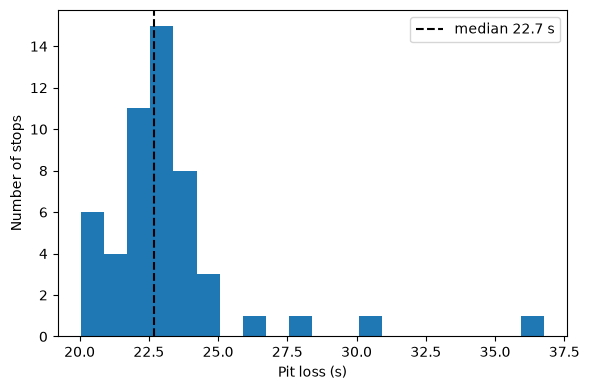

In [28]:
# =================================
# Summary and figure
# =================================

med = stops['loss'].median()
q1, q3 = stops['loss'].quantile([0.25, 0.75])
print(f'median {med:.1f} s, IQR {q1:.1f} to {q3:.1f} s, n = {len(stops)}')
print(stops.sort_values('loss', ascending=False).head(5)[['Driver', 'LapNumber', 'Compound_in', 'Compound_out', 'loss']])

fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(stops['loss'], bins=20)
ax.axvline(med, color='k', linestyle='--', label=f'median {med:.1f} s')
ax.set_xlabel('Pit loss (s)')
ax.set_ylabel('Number of stops')
ax.legend()
fig.tight_layout()
fig.savefig('../figures/07_pit_loss.png', dpi=150)

In [29]:
# =================================
# Putting all the inputs together into one place
# =================================

P = med
RACE_LAPS = 66
AGE_MAX = {'SOFT': 24, 'MEDIUM': 35, 'HARD': 35}
k = {c: beta[f'k_{c}'] for c in deg.COMPOUNDS}
b = {'SOFT': 0.0, 'MEDIUM': beta['b_MEDIUM'], 'HARD': beta['b_HARD']}
print(k)
print(b)
print(round(P, 2))

{'SOFT': np.float64(0.1455804702156342), 'MEDIUM': np.float64(0.12216496132367102), 'HARD': np.float64(0.16095544851138543)}
{'SOFT': 0.0, 'MEDIUM': np.float64(0.5651758580120129), 'HARD': np.float64(0.5993083178104008)}
22.7


In [30]:
# =================================
# The cost of one stint, checked against a loop
# =================================

def stint_cost(compound, n, a0=1, k_scale=1.0):
    """Time (s) a stint of n laps adds through the b and k*age terms."""
    return n * b[compound] + k_scale * k[compound] * (n * a0 + n * (n - 1) / 2)

loop = sum(b['MEDIUM'] + k['MEDIUM'] * age for age in range(4, 4 + 20))
print(stint_cost('MEDIUM', 20, a0=4), loop)

44.288056717631434 44.288056717631434


In [31]:
# =================================
# The cost of an entire race strategy
# =================================

def race_cost(stints, P):
    """Strategy time (s), leaving out terms that are the same for every strategy.
    stints: list of (compound, laps, a0). Returns inf if a rule is broken."""
    if sum(n for _, n, _ in stints) != RACE_LAPS:
        return np.inf
    if len({c for c, _, _ in stints}) < 2:
        return np.inf
    for c, n, a0 in stints:
        if n < 1 or a0 + n - 1 > AGE_MAX[c]:
            return np.inf
    return sum(stint_cost(c, n, a0) for c, n, a0 in stints) + (len(stints) - 1) * P

In [32]:
# =================================
# Testing the functions on real and illegal strategies
# =================================

ver = [('SOFT', 13, 4), ('MEDIUM', 15, 1), ('SOFT', 16, 4), ('MEDIUM', 22, 1)]
print('VER actual  ', round(race_cost(ver, P), 2))
print('M-H 1-stop  ', round(race_cost([('MEDIUM', 33, 1), ('HARD', 33, 1)], P), 2))
print('one compound', race_cost([('MEDIUM', 33, 1), ('MEDIUM', 33, 1)], P))
print('Soft too old', race_cost([('SOFT', 31, 1), ('MEDIUM', 35, 1)], P))
print('60 laps     ', race_cost([('MEDIUM', 30, 1), ('HARD', 30, 1)], P))

VER actual   180.28
M-H 1-stop   219.96
one compound inf
Soft too old inf
60 laps      inf


In [ ]:
# =================================
# A function to tabulate every stint cost
# =================================

A0_NEW = {'SOFT': 1, 'MEDIUM': 1, 'HARD': 1}
A0_USED = {'SOFT': 4, 'MEDIUM': 1, 'HARD': 1}

def cost_table(A0, k_scale=1.0):
    """table[c][n] = cost of an n-lap stint on compound c; inf if beyond the data."""
    table = {}
    for c in deg.COMPOUNDS:
        row = np.full(RACE_LAPS + 1, np.inf)
        for n in range(1, RACE_LAPS + 1):
            if A0[c] + n - 1 <= AGE_MAX[c]:
                row[n] = stint_cost(c, n, A0[c], k_scale)
        table[c] = row
    return table

table = cost_table(A0_NEW)
print(table['SOFT'][[1, 24, 25]])
print(table['MEDIUM'][[1, 35, 36]])

[ 0.14558047 43.67414106         inf]
[ 0.68734082 96.74508066         inf]


In [40]:
# =================================
# 2 functions for searching for one stop count
# =================================

from itertools import combinations

def cost_of_stops(stops_at, table, P):
    """Cheapest legal compound choice for these stop laps: (cost, compounds)."""
    edges = (0,) + tuple(stops_at) + (RACE_LAPS,)
    lengths = [edges[i + 1] - edges[i] for i in range(len(edges) - 1)]
    costs = np.array([[table[c][n] for c in deg.COMPOUNDS] for n in lengths])
    pick = costs.argmin(axis=1)
    total = costs.min(axis=1).sum()
    if np.isinf(total):
        return np.inf, None
    if len(set(pick)) < 2:
        extra = costs - costs.min(axis=1, keepdims=True)
        extra[:, pick[0]] = np.inf
        i = extra.min(axis=1).argmin()
        total += extra[i].min()
        pick[i] = extra[i].argmin()
    return total + len(stops_at) * P, [deg.COMPOUNDS[j] for j in pick]

def best_for_stops(n_stops, table, P):
    """Best legal strategy with n_stops stops: (cost, stop_laps, compounds)."""
    best = (np.inf, None, None)
    for stops_at in combinations(range(1, RACE_LAPS), n_stops):
        total, comps = cost_of_stops(stops_at, table, P)
        if total < best[0]:
            best = (total, stops_at, comps)
    return best

In [41]:
# =================================
# Running and checking it
# =================================

import time

results = {}
for name, A0 in [('all new sets', A0_NEW), ('used Softs', A0_USED)]:
    table = cost_table(A0)
    print(name)
    for n_stops in range(1, 5):
        t0 = time.perf_counter()
        cost, stops_at, comps = best_for_stops(n_stops, table, P)
        dt = time.perf_counter() - t0
        edges = (0,) + stops_at + (RACE_LAPS,)
        stints = [(c, edges[i + 1] - edges[i], A0[c]) for i, c in enumerate(comps)]
        assert np.isclose(race_cost(stints, P), cost)
        seq = '-'.join(c[0] for c in comps)
        print(f'  {n_stops} stops: {cost:7.2f}  stop laps {stops_at}  {seq}  ({dt:.1f} s)')
        results[(name, n_stops)] = (cost, stops_at, comps)

all new sets
  1 stops:  217.86  stop laps (31,)  H-M  (0.0 s)
  2 stops:  162.40  stop laps (22, 44)  M-S-S  (0.0 s)
  3 stops:  158.05  stop laps (15, 32, 49)  M-S-S-S  (0.6 s)
  4 stops:  164.17  stop laps (12, 25, 38, 52)  M-S-S-S-S  (12.5 s)
used Softs
  1 stops:  217.86  stop laps (31,)  H-M  (0.0 s)
  2 stops:  178.13  stop laps (20, 43)  S-M-M  (0.0 s)
  3 stops:  177.01  stop laps (15, 32, 49)  S-M-M-M  (0.6 s)
  4 stops:  185.79  stop laps (12, 25, 38, 52)  S-M-M-M-M  (11.2 s)


In [ ]:
# =================================
# Tabulating every legal strategy
# =================================

def all_strategies(n_stops, table, P):
    """Every legal strategy with n_stops stops, one row each."""
    rows = []
    for stops_at in combinations(range(1, RACE_LAPS), n_stops):
        total, comps = cost_of_stops(stops_at, table, P)
        if np.isfinite(total):
            rows.append({'stops': n_stops, 'first': stops_at[0], 'stop_laps': stops_at,
                         'cost': total, 'seq': '-'.join(c[0] for c in comps)})
    return pd.DataFrame(rows)

table_used = cost_table(A0_USED)
allstrat = pd.concat([all_strategies(n, table_used, P) for n in (1, 2, 3)], ignore_index=True)
allstrat['delta'] = allstrat['cost'] - allstrat['cost'].min()
print(len(allstrat), allstrat.groupby('stops').size().to_dict())
allstrat.sort_values('cost').head(10)

28220 {1: 5, 2: 775, 3: 27440}


,stops,first,stop_laps,cost,seq,delta
15438,3,17,"(17, 34, 49)",177.010908,M-M-S-M,0.000000
13605,3,15,"(15, 32, 49)",177.010908,S-M-M-M,0.000000
15375,3,17,"(17, 32, 49)",177.010908,M-S-M-M,0.000000
15440,3,17,"(17, 34, 51)",177.010908,M-M-M-S,0.000000
15469,3,17,"(17, 35, 50)",177.133073,M-M-S-M,0.122165
16278,3,18,"(18, 33, 49)",177.133073,M-S-M-M,0.122165
15470,3,17,"(17, 35, 51)",177.133073,M-M-M-S,0.122165
13572,3,15,"(15, 31, 49)",177.133073,S-M-M-M,0.122165
16279,3,18,"(18, 33, 50)",177.133073,M-S-M-M,0.122165
14525,3,16,"(16, 33, 48)",177.133073,M-M-S-M,0.122165


In [38]:
# =================================
# The windows
# =================================

curve = allstrat.groupby(['stops', 'first'])['delta'].min().unstack(0)
for n in (2, 3):
    for tol in (1.0, 2.0):
        ok = curve.index[curve[n] - curve[n].min() <= tol]
        print(f'{n}-stop, within {tol:.0f} s of its best: first stop on laps {list(ok)}')

2-stop, within 1 s of its best: first stop on laps [18, 19, 20, 21, 22, 23, 24, 25, 26]
2-stop, within 2 s of its best: first stop on laps [16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27]
3-stop, within 1 s of its best: first stop on laps [12, 13, 14, 15, 16, 17, 18, 19, 20]
3-stop, within 2 s of its best: first stop on laps [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


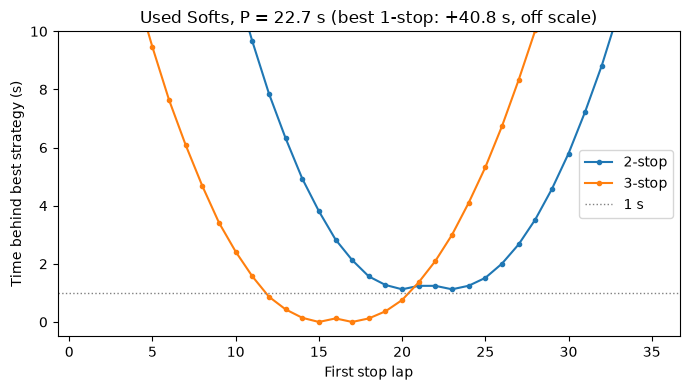

In [39]:
# =================================
# Figure
# =================================

fig, ax = plt.subplots(figsize=(7, 4))
for n in (2, 3):
    ax.plot(curve.index, curve[n], marker='.', label=f'{n}-stop')
ax.axhline(1.0, color='grey', linestyle=':', linewidth=1, label='1 s')
ax.set_ylim(-0.5, 10)
ax.set_xlabel('First stop lap')
ax.set_ylabel('Time behind best strategy (s)')
ax.set_title(f'Used Softs, P = {P:.1f} s (best 1-stop: +{curve[1].min():.1f} s, off scale)')
ax.legend()
fig.tight_layout()
fig.savefig('../figures/07_first_stop.png', dpi=150)

In [42]:
# =================================
# One function that summarises a scenario
# =================================

def summarise(A0, k_scale, P):
    """Best 2- and 3-stop, their gap, the tie pit loss, and the 1 s windows."""
    table = cost_table(A0, k_scale)
    s = pd.concat([all_strategies(n, table, P) for n in (1, 2, 3)], ignore_index=True)
    best = s.loc[s.groupby('stops')['cost'].idxmin()].set_index('stops')
    out = {'cost2_minus_cost3': best.loc[2, 'cost'] - best.loc[3, 'cost']}
    out['P_tie'] = P + out['cost2_minus_cost3']
    for n in (2, 3):
        fam = s[s['stops'] == n]
        firsts = fam.loc[fam['cost'] <= fam['cost'].min() + 1.0, 'first']
        out[f'win{n}'] = f'{firsts.min()}-{firsts.max()}'
        out[f'best{n}'] = f"{best.loc[n, 'seq']} {best.loc[n, 'stop_laps']}"
    return out

In [43]:
# =================================
# Running the 6 scenarios
# =================================

rows = []
for name, A0 in [('new sets', A0_NEW), ('used Softs', A0_USED)]:
    for ks in (0.8, 1.0, 1.2):
        rows.append({'a0': name, 'k_scale': ks, **summarise(A0, ks, P)})
sens7 = pd.DataFrame(rows)
sens7

,a0,k_scale,cost2_minus_cost3,P_tie,win2,best2,win3,best3
0,new sets,0.8,-0.305671,22.391810,18-24,"M-S-S (21, 43)",11-20,"M-S-S-S (15, 32, 49)"
1,new sets,1.0,4.348972,27.046453,19-24,"M-S-S (22, 44)",13-20,"M-S-S-S (15, 32, 49)"
2,new sets,1.2,9.026114,31.723596,20-25,"M-S-S (22, 44)",13-19,"M-S-S-S (16, 32, 49)"
3,used Softs,0.8,-2.506285,20.191197,18-26,"S-S-M (21, 42)",13-21,"S-S-S-M (16, 32, 48)"
4,used Softs,1.0,1.123930,23.821411,18-26,"S-M-M (20, 43)",12-20,"S-M-M-M (15, 32, 49)"
5,used Softs,1.2,6.453388,29.150870,17-26,"S-M-M (20, 43)",12-20,"S-M-M-M (15, 32, 49)"


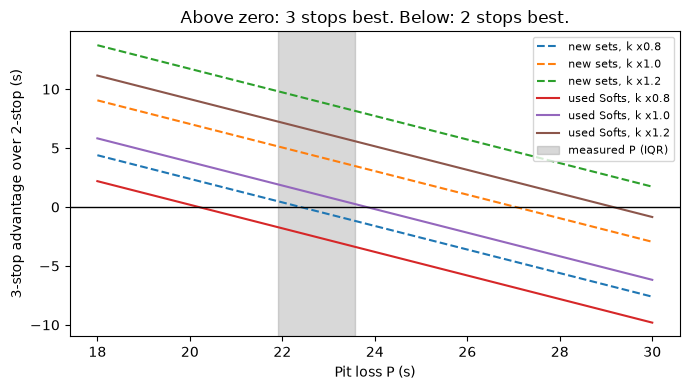

In [44]:
# =================================
# The sensitivity figure
# =================================

P_axis = np.linspace(18, 30, 100)
fig, ax = plt.subplots(figsize=(7, 4))
for r in sens7.itertuples():
    style = '-' if r.a0 == 'used Softs' else '--'
    ax.plot(P_axis, r.cost2_minus_cost3 - (P_axis - P), style, label=f'{r.a0}, k x{r.k_scale}')
ax.axhline(0, color='k', linewidth=1)
ax.axvspan(q1, q3, color='grey', alpha=0.3, label='measured P (IQR)')
ax.set_xlabel('Pit loss P (s)')
ax.set_ylabel('3-stop advantage over 2-stop (s)')
ax.set_title('Above zero: 3 stops best. Below: 2 stops best.')
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig('../figures/07_sensitivity.png', dpi=150)

In [ ]:
# =================================
# A check that a four stop strategy never wins
# =================================

for name, A0 in [('new sets', A0_NEW), ('used Softs', A0_USED)]:
    t = cost_table(A0, 1.2)
    c3 = best_for_stops(3, t, P - 2)[0]
    c4 = best_for_stops(4, t, P - 2)[0]
    print(f'{name}: 4-stop minus 3-stop = {c4 - c3:.2f} s')

new sets: 4-stop minus 3-stop = 1.20 s
used Softs: 4-stop minus 3-stop = 3.66 s


In [46]:
# =================================
# Cost every driver's actual strategy
# =================================

st = (laps.groupby(['Driver', 'Stint'])
          .agg(compound=('Compound', 'first'), n=('LapNumber', 'size'), a0=('TyreLife', 'min'))
          .reset_index())

def actual_cost(g, P):
    """Cost of the stints a driver actually ran, with their real starting ages."""
    return sum(stint_cost(c, n, a0) for c, n, a0 in zip(g['compound'], g['n'], g['a0'])) + (len(g) - 1) * P

real = pd.DataFrame({
    'seq': st.groupby('Driver')['compound'].agg(lambda s: '-'.join(c[0] for c in s)),
    'stints': st.groupby('Driver')['n'].agg(list),
    'last_lap': laps.groupby('Driver')['LapNumber'].max(),
    'cost': st.groupby('Driver').apply(actual_cost, P=P),
})
real['vs_best'] = real['cost'] - results[('used Softs', 3)][0]
print(real['seq'].value_counts().to_dict())
real.sort_values('cost')

{'S-M-S-S': 6, 'S-M-M-S': 3, 'S-S-M': 2, 'S-M': 2, 'S-S-M-S': 2, 'S-M-S-M-S': 1, 'S-M-H': 1, 'M-S-M-S': 1, 'S-M-M': 1, 'S-M-S-M': 1}


C:\Users\Ryan\AppData\Local\Temp\ipykernel_11576\2879288281.py:17: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  'cost': st.groupby('Driver').apply(actual_cost, P=P),


,seq,stints,last_lap,cost,vs_best
Driver,,,,,
ZHO,S-M,"[10, 18]",28.0,61.767781,-115.243127
LEC,S-M,"[21, 6]",27.0,62.283089,-114.727818
LAT,S-M-S-S,"[12, 14, 24, 14]",64.0,165.261974,-11.748934
ALO,S-M-S-S,"[10, 21, 22, 12]",65.0,167.869236,-9.141672
STR,S-S-M-S,"[14, 13, 19, 19]",65.0,172.349342,-4.661566
ALB,S-M-S-M-S,"[11, 14, 20, 9, 10]",64.0,174.668264,-2.342644
GAS,S-M-S-S,"[10, 19, 17, 19]",65.0,175.705846,-1.305062
OCO,S-M-S-S,"[13, 22, 17, 14]",66.0,175.780616,-1.230292
TSU,S-M-S-S,"[11, 21, 20, 13]",65.0,176.021742,-0.989165


In [ ]:
# =================================
# Making a function to search with a cap on medium stints
# =================================

from itertools import product

def best_constrained(n_stops, table, P, max_medium):
    """Best strategy using at most max_medium Medium stints (full search over compounds)."""
    seqs = [s for s in product(deg.COMPOUNDS, repeat=n_stops + 1)
            if len(set(s)) >= 2 and s.count('MEDIUM') <= max_medium]
    best = (np.inf, None, None)
    for stops_at in combinations(range(1, RACE_LAPS), n_stops):
        edges = (0,) + stops_at + (RACE_LAPS,)
        lengths = [edges[i + 1] - edges[i] for i in range(n_stops + 1)]
        for s in seqs:
            total = sum(table[c][n] for c, n in zip(s, lengths))
            if total < best[0]:
                best = (total, stops_at, s)
    return best[0] + n_stops * P, best[1], best[2]

In [48]:
# =================================
# Running the caps
# =================================

rows = []
for max_m in (3, 2, 1):
    for n_stops in (2, 3):
        cost, stops_at, seq = best_constrained(n_stops, table_used, P, max_m)
        stints = [b - a for a, b in zip((0,) + stops_at, stops_at + (RACE_LAPS,))]
        rows.append({'max_mediums': max_m, 'stops': n_stops, 'cost': round(cost, 2),
                     'seq': '-'.join(c[0] for c in seq), 'stints': stints})
capped = pd.DataFrame(rows)
capped

,max_mediums,stops,cost,seq,stints
0,3,2,178.13,S-M-M,"[20, 23, 23]"
1,3,3,177.01,M-M-M-S,"[17, 17, 17, 15]"
2,2,2,178.13,S-M-M,"[20, 23, 23]"
3,2,3,178.26,S-M-S-M,"[15, 18, 15, 18]"
4,1,2,181.21,S-S-M,"[21, 21, 24]"
5,1,3,179.52,S-M-S-S,"[16, 18, 16, 16]"
